# CEMSIE FMCW radar practical

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy
import xarray as xr
from matplotlib.transforms import offset_copy

# Part I - FMCW Radar principle

**Frequency-Modulated Continuous Wave (FMCW) radars** measure the range (and, from the Doppler shift, the velocity) of a target by continuously transmitting a signal whose frequency changes linearly with time (a "**chirp**") rather than transmitting short pulses. It is the operating principle behind the surface-based scatterometers used during CEMSIE.

Instead of timing how long a short pulse takes to return, an FMCW radar converts the round-trip travel time into a **frequency difference** between the transmitted and received chirps, which can be measured very precisely with an Fourier transform.

In this part we build an FMCW radar simulation from scratch, in five steps:

1. Generate the transmitted chirp.
2. Simulate the received echo — a delayed, weaker copy of the chirp reflected from a target at a known range.
3. **Mix** (multiply) the transmitted and received signals to obtain a low-frequency "beat" signal.
4. Take the Fourier transform of the beat signal to find the beat frequency.
5. Convert the beat frequency back into target range.

The code used for this simulation is adapted from **Robbie Mallett's video: https://www.youtube.com/watch?v=Phi_AyIW3jY**

## System block diagram

A basic FMCW radar consists of the following functional blocks:

- **RF generator:** Produces the continuous-wave signal whose frequency is swept ("chirp") linearly over time.
- **Power divider:** Splits the generator's output into two paths: one goes to the transmitting antenna, and a second is send as reference to the mixer.
- **Transmitting antenna:** radiates the signal towards the target.
- **Target:** reflects a delayed, attenuated copy of the chirp back to the radar. The round-trip delay is $\tau = 2R/c$, where $R$ is the target range and $c$ the speed of light.
- **Receiving antenna:** Captures the backscattered sigal from the target.
- **Pre-amplifier:** Low-noise amplifier (LNA) that boosts the weak received signal before further processing.
- **Mixer:** The heart of FMCW ranging. It multiplies the amplified received signal with the reference chirp captured from the power divider. This produces sum and difference frequency components; the difference frequency (the "beat frequency") is directly proportional to the round-trip delay and hence the target's range.
- **Low-pass filter:** Removes the high-frequency sum component to keep only the low-frequency beat signal.
- **Aamplifier:** Boosts the signal before digitization.
- **ADC:** Analog to digital converter.

The figure below draws this signal chain. Image source: https://en.wikipedia.org/wiki/Continuous-wave_radar

<img src="images/FMCW_block_diagram.png" alt="FMCW radar block diagram" width="600">

## The transmit chirp

The transmit chirp is a linear frequency ramp between $f_0$ and $f_1$ of duration $T$. The bandwith is $B = f_0 - f_1$.

Therefore, the **chirp slope** is $$S = \frac{B}{T} = \frac{f_1 - f_0}{T}$$

<img src="images/transmit_chirp_f_v_t.png" alt="Transmit chirp" width="600">

**Task 1a :** with the help of the `scipy.signal` documentation, generate a linear chirp using the parameters defined below. 

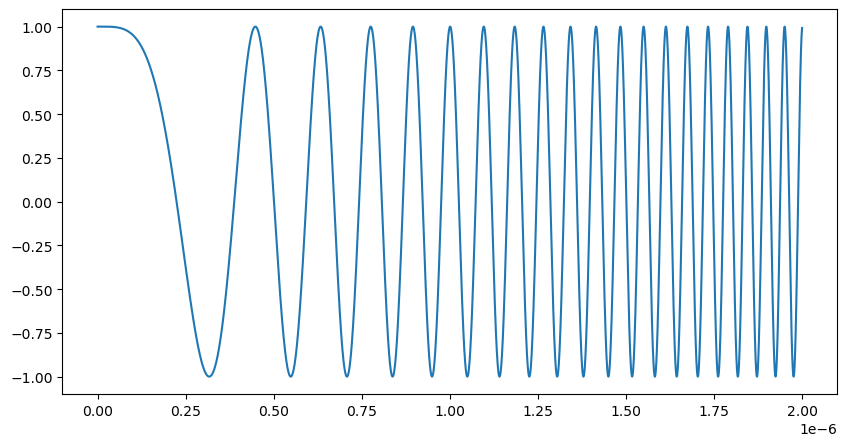

In [2]:
T = 2e-3  # chirp length (s)
f0 = 30e9 # lower frequency (Hz)
f1 = 10e9 # upper frequency (Hz)

n_samples = int(5e6) # dimensionless
sampling_rate = n_samples / T
t_axis = np.linspace(0, T, n_samples)

############## TO COMPLETE: ##############

transmit_chirp = scipy.signal.chirp(t_axis, f0=f0, f1=f1, t1=T, method='linear')

##########################################


fig, ax = plt.subplots(1, 1, figsize=(10, 5))
n_samples_plot = int(5e3)
ax.plot(t_axis[:n_samples_plot], transmit_chirp[:n_samples_plot])

## The receive chirp

The receive chirp is a delayed (the delay is noted $\tau$) and attenuated version of the transmit chirp.

**Task 1b :** complete the expression of the delay $\tau$.

In [3]:
c = 3e8          # speed of light (m/s)
target_range = 2 # simulated target range (m). We will try to retreive this number - normally unknown - with some signal processing.

############## TO COMPLETE: ##############

tau = 2 * target_range / c

##########################################

The **beat frequency** $\Delta f$ is the difference between the transmit and receive frequencies: $$\Delta f = f_{Tx}(t) - f_{Rx}(t)$$

<img src="images/receive_chirp_f_v_t.png" alt="Transmit chirp" width="600">

Since the frequency ramp is linear, the beat frequency is constant and can be written: $$\Delta f = S\,\tau = \frac{f_1-f_0}{T}\cdot\frac{2R}{c}$$
where:
- $R$ is the range of the target,
- $c$ is the speed of light

Therefore, $\Delta f $ varies linearly with the target range $R$.

## Simulating the received echo and mixing

To simulate the receiver, the transmitted chirp is time-shifted by `time_delay` ($\tau = 2R/c$) to create `receive_chirp` — this stanscat in for the echo reflected from the target. (A real echo would also be attenuated and noisy, but for this exercise we only care about its frequency content.)

The two signals are then **mixed** (multiplied sample-by-sample) to produce `mixed`. Multiplying two sinusoiscat of frequencies $f_{TX}(t)$ and $f_{RX}(t)$ produces components at the *sum* $f_{TX}(t)+f_{RX}(t)$ (fast) and the *difference* $f_{TX}(t)-f_{RX}(t) = \Delta f$ (slow, and constant during the overlap of the two chirps). The plot below shows the mixed signal in the time domain: the fast oscillation is the sum-frequency term, while the much slower envelope corresponds to $\Delta f$.

**Task 1c :** complete the expression of the mixed signal.

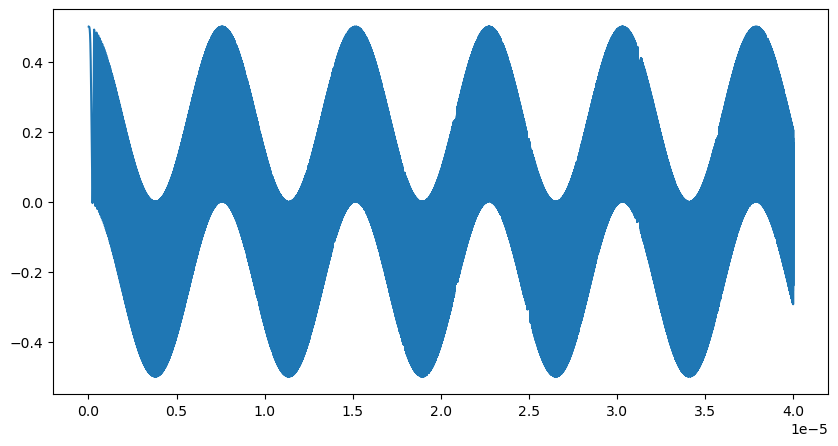

In [4]:
samples_until_return = int(sampling_rate * tau) # n samples before the return signal starts being received
t_axis = np.linspace(0, T + tau , n_samples + samples_until_return)
nan_pad = np.full(samples_until_return, np.nan) # pad with NaN values
Gr = 0.5 # gain of the return signal (dimensionless)
receive_chirp = np.append(nan_pad, Gr * transmit_chirp, axis=0)
transmit_chirp = np.append(transmit_chirp, nan_pad, axis=0)

############## TO COMPLETE: ##############

mixed = receive_chirp * transmit_chirp

##########################################

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
n_samples_plot = int(1e5)
ax.plot(t_axis[:n_samples_plot], mixed[:n_samples_plot])

## Extracting the beat frequency with a Fourier transform

A real receiver would low-pass filter `mixed` to remove the sum-frequency term before digitizing it; here we instead go straight to the FFT of the overlapping region of `mixed` (the portion where both the transmitted and received chirps are present.

**Task 1d :** With the help of the `scipy.fft` documentation, complete the expression of the mixed signal FFT, power and frequency axis.

Text(0, 0.5, 'Power Density')

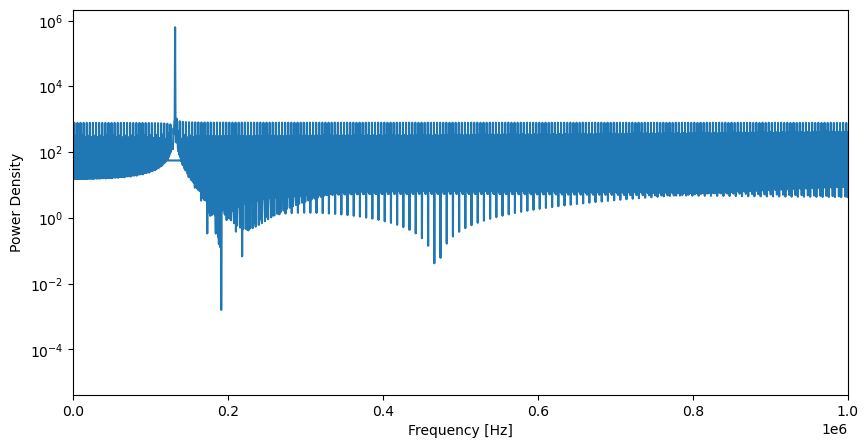

In [5]:
############## TO COMPLETE: ##############

fft = scipy.fft.fft(mixed[samples_until_return: -samples_until_return])
fft_power = abs(fft)
xf = scipy.fft.fftfreq(n_samples - samples_until_return, T / (n_samples - samples_until_return))

##########################################

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(xf, fft_power)
ax.set_xlim(0, 1e6)
ax.set_yscale('log')
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('Power Density')

**Task 1e :** Extract the beat frequency $\Delta f$ from the spectrum.

In [6]:
############## TO COMPLETE: ##############

f_beat = xf[np.argmax(fft_power)]

##########################################

## From beat frequency to range

Recall :

$$\Delta f = S\,\tau = \frac{f_1-f_0}{T}\cdot\frac{2R}{c}$$

Therefore:

$$R = \frac{c\,\Delta f\,T}{2(f_1-f_0)}$$

**Task 1f :** calculate the range of the target.

In [7]:
############## TO COMPLETE: ##############

radar_range = np.abs(c * f_beat * T / (2 * (f1 - f0)))

##########################################

print(f'Radar range: {radar_range} m')

Radar range: 1.98 m


# Part II - FMCW radar with multiple targets

In this part, we extend the simulation to a scene with **several targets at different ranges**, instead of just one.

The transmitted chirp reflects off every target, so the received signal is the superposition of several delayed and attenuated copies of the transmit chirp — one per target. Since mixing (multiplication with the reference chirp) distributes over addition, the mixed signal is simply the **sum of the single-target beat signals** from Part I, each oscillating at its own beat frequency $\Delta f_i = S\,\tau_i$.

## The transmit chirp

We regenerate the same transmit chirp as in Part I.

**Task 2a :** generate the transmit chirp.

In [8]:
T = 2e-3  # chirp length (s)
f0 = 30e9 # lower frequency (Hz)
f1 = 10e9 # upper frequency (Hz)

n_samples = int(5e6) # dimensionless
sampling_rate = n_samples / T
t_axis = np.linspace(0, T, n_samples)

############## TO COMPLETE: ##############

transmit_chirp = scipy.signal.chirp(t_axis, f0=f0, f1=f1, t1=T, method='linear')

##########################################

## Multiple targets

We now place three targets at ranges 1, 2 and 3 m, and compute the round-trip delay $\tau_i$ of each one.

**Task 2b :** write the expression for the delay list.

In [9]:
c = 3e8                     # speed of light (m/s)
target_ranges = [1, 2, 3]   # simulated target ranges (m)
Gr = 0.5                    # gain of the return signal, same for every target (dimensionless)

############## TO COMPLETE: ##############

taus = [2 * R / c for R in target_ranges]  # round-trip delay of each target (s)

##########################################

## Simulating the received echoes and mixing

Each target contributes a copy of the transmit chirp, delayed by its own $\tau_i$ and attenuated by `Gr`. Unlike in Part I, we cannot pad the missing samples with `NaN`, since summing several echoes together would turn every sample touched by a `NaN` into `NaN`. Instead, each echo is zero-padded so all echoes share the same length and can simply be summed to build the total received signal `receive_chirp`.

The transmit chirp is zero-padded the same way so that `transmit_chirp` and `receive_chirp` have matching lengths, then mixed (multiplied) as in Part I.

**Tals 2c :** Write the expression of the mixed signal.

Text(0, 0.5, 'Amplitude')

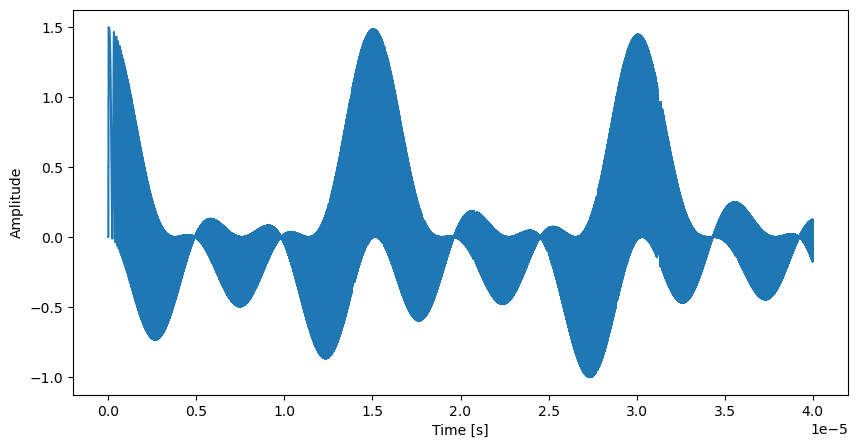

In [10]:
delay_samples = [int(sampling_rate * tau) for tau in taus] # n samples before each return signal starts being received
max_delay_samples = max(delay_samples)

t_axis = np.linspace(0, T + max(taus), n_samples + max_delay_samples)

# sum of the delayed, attenuated, zero-padded echoes from every target
receive_chirp = np.zeros(n_samples + max_delay_samples)
for d in delay_samples:
    receive_chirp += np.pad(Gr * transmit_chirp, (d, max_delay_samples - d))

transmit_chirp = np.pad(transmit_chirp, (0, max_delay_samples))

############## TO COMPLETE: ##############

mixed = receive_chirp * transmit_chirp

##########################################

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
n_samples_plot = int(1e5)
ax.plot(t_axis[:n_samples_plot], mixed[:n_samples_plot])
ax.set_xlabel('Time [s]')
ax.set_ylabel('Amplitude')

## Extracting the beat frequencies with a Fourier transform

The beat frequency of each target is constant only once *every* target has started returning and while the transmit chirp is still being emitted, i.e. for $t \in [\tau_{max}, T]$. We therefore take the FFT of `mixed` restricted to that common overlap region, exactly as in Part I but using the delay of the *farthest* target, `max_delay_samples`.

Because the mixed signal is now the sum of three beat signals, its power spectrum shows three separate peaks, one per target.

**Task 2d :** Write the expressions of the FFT, power and frequency axis of the mixed signal. 

Text(0, 0.5, 'Power Density')

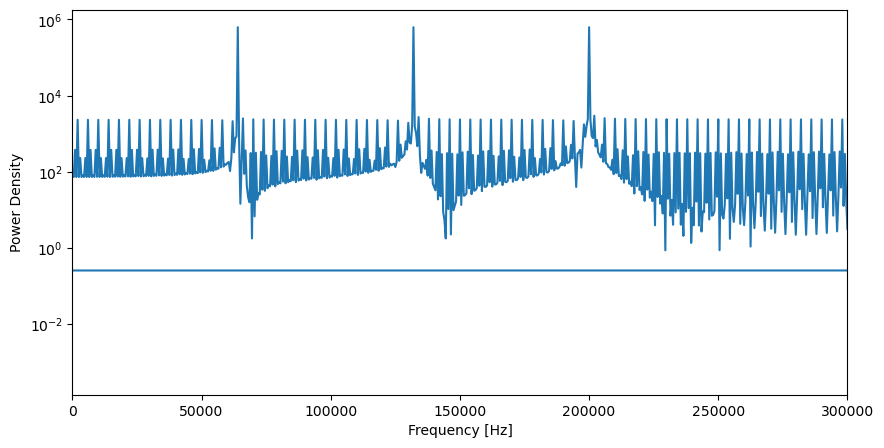

In [11]:
overlap = mixed[max_delay_samples : -max_delay_samples]
n_valid = len(overlap)

############## TO COMPLETE: ##############

fft = scipy.fft.fft(overlap)
fft_power = abs(fft)
xf = scipy.fft.fftfreq(n_valid, T / n_valid)

##########################################


fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(xf, fft_power)
ax.set_xlim(0, 3e5)
ax.set_yscale('log')
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('Power Density')

## From beat frequencies to ranges

Each peak in the spectrum above corresponscat to one target. We find them with `scipy.signal.find_peaks` (keeping only peaks above half the maximum, to reject FFT side-lobes), then convert every beat frequency to a range using the same relation as in Part I:

$$R = \frac{c\,\Delta f\,T}{2(f_1-f_0)}$$

**Task 2e :** Complete the expression of the target ranges.

In [12]:
positive = xf > 0
xf_pos = xf[positive]
fft_power_pos = fft_power[positive]

peak_idx, _ = scipy.signal.find_peaks(fft_power_pos, height=0.5 * fft_power_pos.max())
f_beats = xf_pos[peak_idx]

############## TO COMPLETE: ##############

radar_ranges = np.sort(np.abs(c * f_beats * T / (2 * (f1 - f0))))

##########################################

for r in radar_ranges:
    print(f'Detected target range: {r:.2f} m')

Detected target range: 0.96 m
Detected target range: 1.98 m
Detected target range: 3.00 m


# Part III - CEMSIE data analysis

In this part we read and analyse data from the UofM L-band scatterometter deployed during the CEMSIE fieldwork campaign in April-May 2026. The following processing steps have been done:

1. calibration
2. power vs. range calculation (using a similar script as developped in the above parts)
3. $\sigma_0$ calculation (normalized peak power)
4. outliers filtering
5. interpolation on a time-constant grid
6. selection of data between April 25 and May 8

The cell below loads the data.

In [13]:
scat = xr.open_dataset("./data/UofM_Lscat.nc")
scat

<xarray.Dataset> Size: 6MB
Dimensions:  (time: 243, pol: 4, elev: 13, az: 60)
Coordinates:
  * time     (time) datetime64[ns] 2kB 2026-04-25T12:40:30 ... 2026-05-08T22:...
  * pol      (pol) <U2 32B 'VV' 'VH' 'HV' 'HH'
  * elev     (elev) int64 104B 0 5 10 15 20 25 30 35 40 45 50 55 60
  * az       (az) float64 480B -25.0 -24.15 -23.31 -22.46 ... 23.31 24.15 25.0
Data variables:
    nrcs     (time, pol, elev, az) float64 6MB ...
    session  (time) int64 2kB ...
    height   (elev) float64 104B ...

We start with plotting the azimuth-averaged $\sigma_0$ time series.

**Task 3a:** Using the `numpy.nanmean` function, complete the code below to average the data over azimuth. On these plots, the light blue area represents the blizzard that happened on May 1st, which resulted in important snow redistribution. What observations can you make on these graphs?

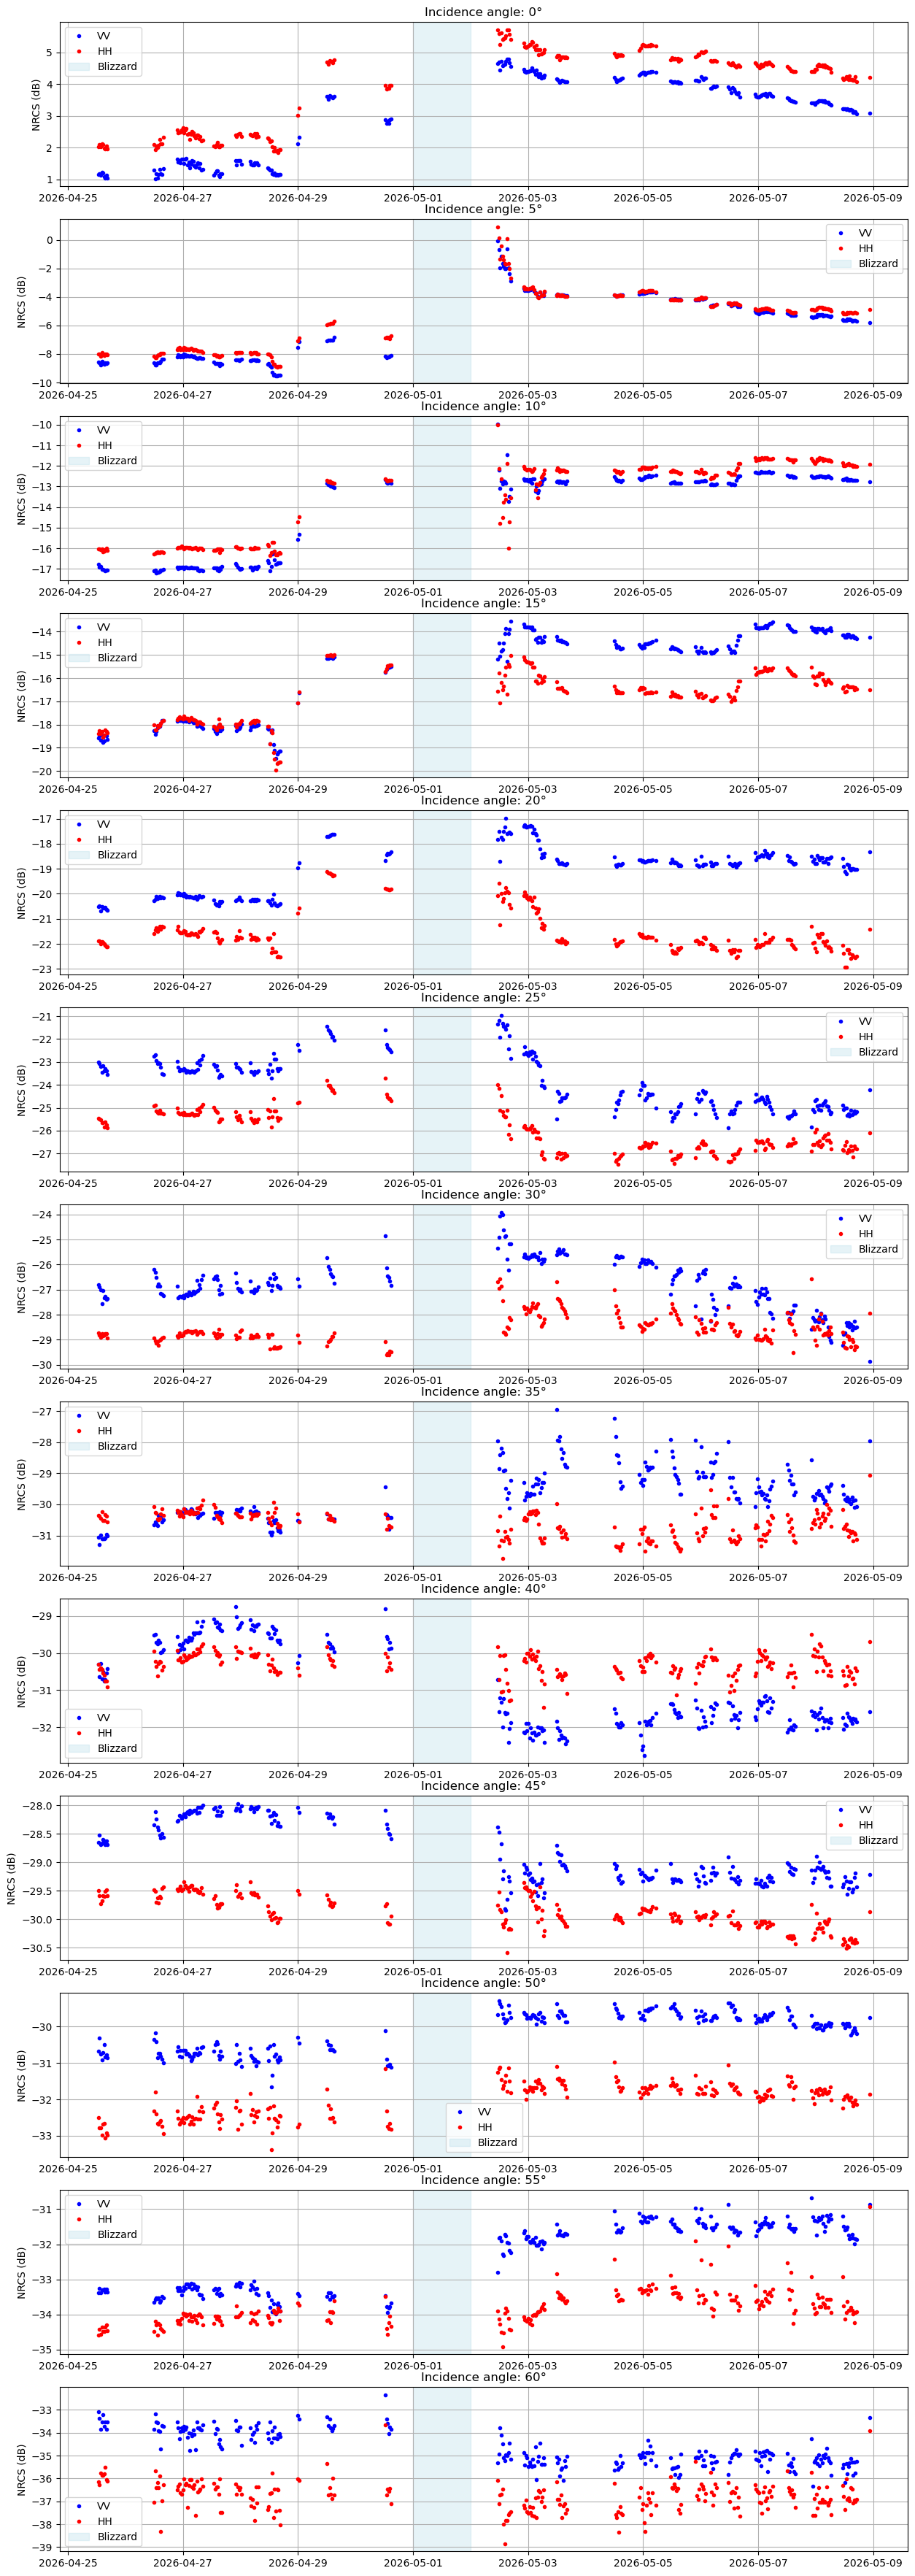

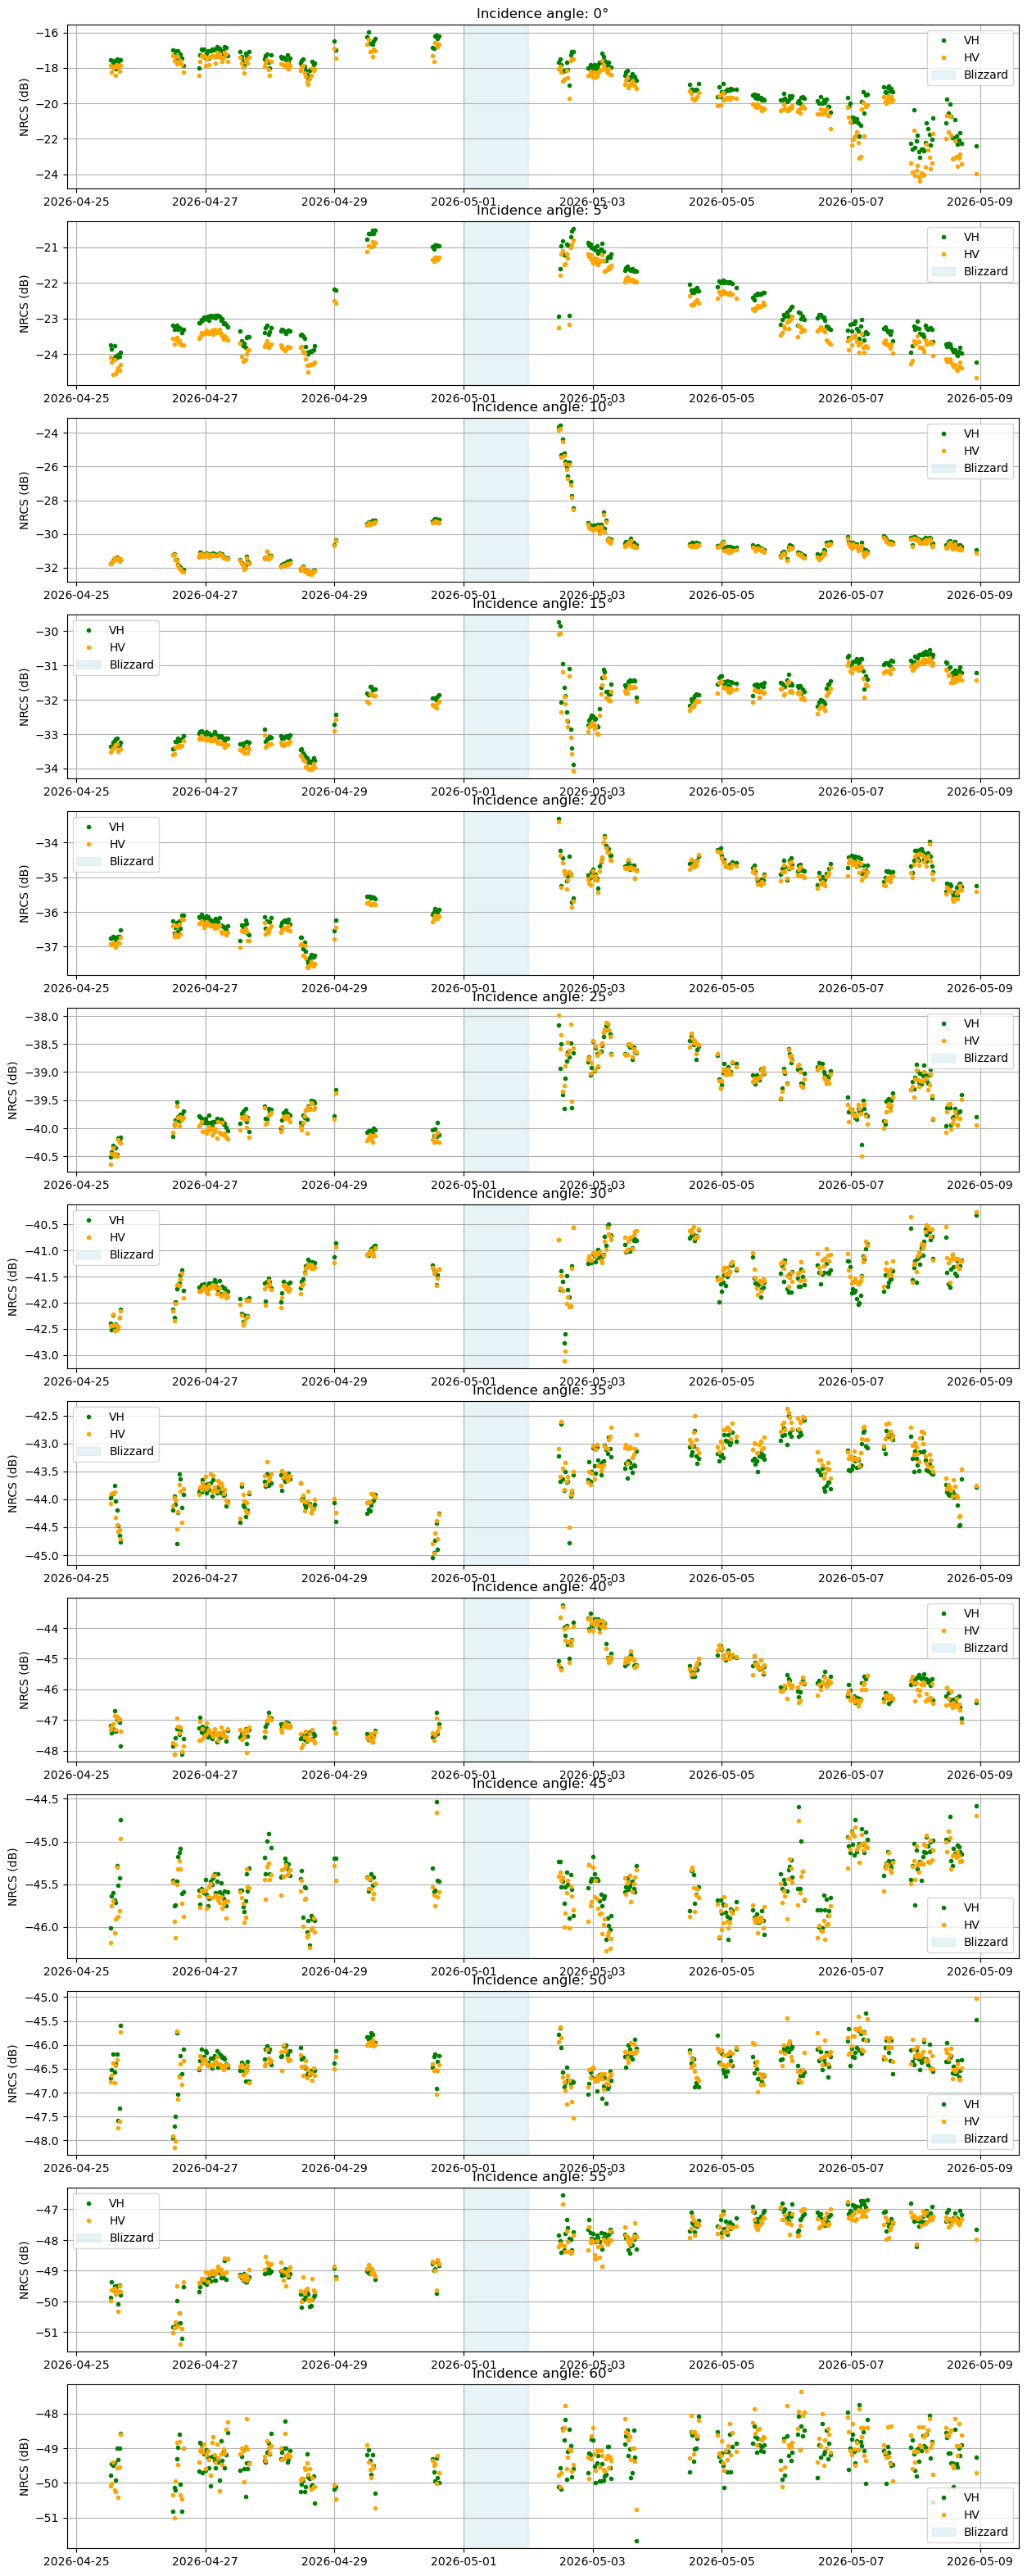

In [14]:
## plot scat timeseries (averaged over azimuth)

fig, axs = plt.subplots(nrows=scat.sizes['elev'], figsize=(15, 45))
for i, angle in enumerate(scat.elev.values):

    ############## TO COMPLETE: ##############

    axs[i].plot(scat["time"], np.nanmean(scat["nrcs"].sel(pol="VV", elev=angle).values, axis=-1), color="blue", marker=".", linestyle="none", label="VV") # plot the azimuth averaged VV channel for incidence angle "angle"
    axs[i].plot(scat["time"], np.nanmean(scat["nrcs"].sel(pol="HH", elev=angle).values, axis=-1), color="red", marker=".", linestyle="none", label="HH") # plot the azimuth averaged HH channel for incidence angle "angle"

    ##########################################

    # blizzard
    start_3, end_3 = np.datetime64("2026-05-01"), np.datetime64("2026-05-02")
    axs[i].axvspan(start_3, end_3, color="lightblue", alpha=0.3, label="Blizzard")

    axs[i].set_title(f"Incidence angle: {angle}°")
    axs[i].set_ylabel("NRCS (dB)")

    axs[i].legend()
    axs[i].grid()

# VH HV
fig, axs = plt.subplots(nrows=scat.sizes["elev"], figsize=(15, 40))

for i, angle in enumerate(scat.elev.values):

    ############## TO COMPLETE: ##############

    axs[i].plot(scat["time"], np.nanmean(scat["nrcs"].sel(pol="VH", elev=angle).values, axis=-1), color="green", marker=".", linestyle="none", label="VH") # plot the azimuth averaged VH channel for incidence angle "angle"
    axs[i].plot(scat["time"], np.nanmean(scat["nrcs"].sel(pol="HV", elev=angle).values, axis=-1), color="orange", marker=".", linestyle="none", label="HV") # plot the azimuth averaged HV channel for incidence angle "angle"
    
    ##########################################

    # blizzard
    start_3, end_3 = np.datetime64("2026-05-01"), np.datetime64("2026-05-02")
    axs[i].axvspan(start_3, end_3, color="lightblue", alpha=0.3, label="Blizzard")

    axs[i].set_title(f"Incidence angle: {angle}°")
    axs[i].set_ylabel("NRCS (dB)")

    axs[i].legend()
    axs[i].grid()

Let's now have a look at the spacial distribution of $\sigma_0$ within the footprint for a few particular timestamps.

**Task 3b :** Complete the code below to select four dates and plot the time-averaged spacial repartition of $\sigma_0$ in the footprint of the instrument. What differences do you observe?

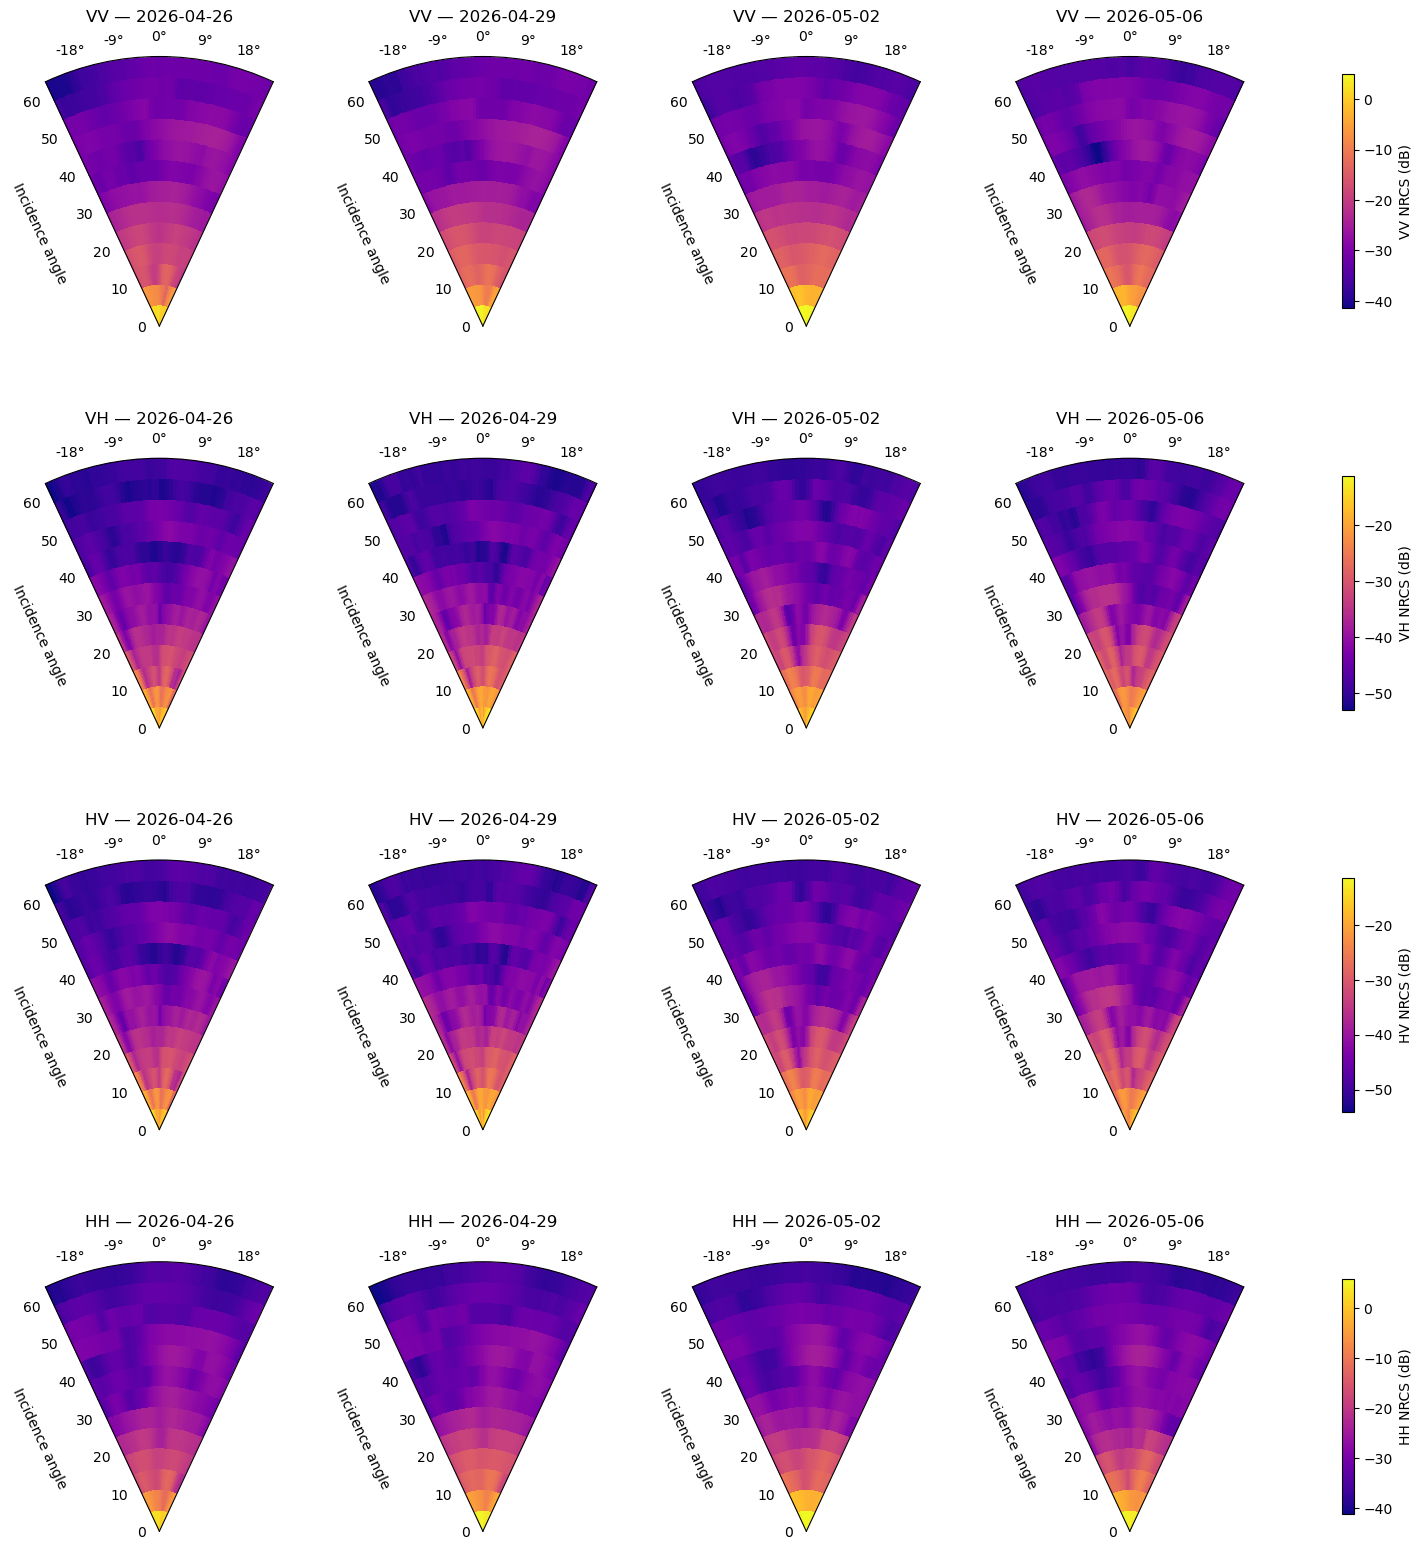

In [15]:
## select 4 dates and plot the polar plots of the NRCS for each polarization

############## TO COMPLETE: ##############

# select four dates
dates = [
    np.datetime64("2026-04-26"),
    np.datetime64("2026-04-29"),
    np.datetime64("2026-05-02"),
    np.datetime64("2026-05-06")
]

##########################################

# NRCS averaged over every scat acquisition on each selected day, for every polarization
pols = scat["pol"].values  # VV, VH, HV, HH

nrcs_sel = {
    pol: [

        ############## TO COMPLETE: ##############

        # select the polarisation channel "pol", filter by date and average over time
        scat["nrcs"].sel(pol=pol).where(scat["time"].dt.date == date, drop=True).mean(dim="time", skipna=True)

        ##########################################
        for date in dates
    ]
    for pol in pols
}
# color scale shared across dates, but computed separately for each polarization
nrcs_vmin = {pol: min(np.nanmin(n.values) for n in nrcs_sel[pol]) for pol in pols}
nrcs_vmax = {pol: max(np.nanmax(n.values) for n in nrcs_sel[pol]) for pol in pols}

az_rad = np.deg2rad(scat["az"].values)  # scatterometer azimuth, radians
elev = scat["elev"].values              # scatterometer elevation (incidence) angle, deg

fig, axs = plt.subplots(len(pols), len(dates), figsize=(5 * len(dates), 5 * len(pols)), subplot_kw={"projection": "polar"})

for row, pol in zip(axs, pols):
    for ax, date, nrcs in zip(row, dates, nrcs_sel[pol]):

        pcm2 = ax.pcolormesh(az_rad, elev, nrcs.values, cmap="plasma", shading="auto", vmin=nrcs_vmin[pol], vmax=nrcs_vmax[pol])

        ax.set_thetamin(-25)
        ax.set_thetamax(25)
        ax.set_theta_zero_location("N")
        ax.set_theta_direction(-1)  # positive angles on the right
        ax.set_title(f"{pol} — {date}")
        ax.grid(False)

        # ground range label along the left edge, pushed further out to clear the radial tick labels
        edge = np.deg2rad(-25)
        label_offset = offset_copy(ax.transData, fig, x=-50 * np.cos(edge), y=50 * np.sin(edge), units="points")
        ax.text(edge, elev.max() / 2, "Incidence angle", rotation=-65, rotation_mode="anchor", ha="center", va="center", transform=label_offset)
        
        

    fig.colorbar(pcm2, ax=row, label=f"{pol} NRCS (dB)", shrink=0.7)

Let's now load the corresponding TLS data and compare it to the scatterometter scans. The cell below loads the TLS data. The following processing steps have been pre-applied:

1. alignment/merge of two different point clouds.
2. georeferencing
3. rasterization
4. crop to the scatterometter footprint.

In [16]:
tls = xr.open_dataset("./data/TLS_UofM_wedge.nc")
tls

<xarray.Dataset> Size: 2MB
Dimensions:  (time: 13, y: 161, x: 162)
Coordinates:
  * time     (time) datetime64[ns] 104B 2026-04-26 2026-04-27 ... 2026-05-10
  * y        (y) float64 1kB 7.66e+06 7.66e+06 7.66e+06 ... 7.66e+06 7.66e+06
  * x        (x) float64 1kB 4.855e+05 4.855e+05 ... 4.855e+05 4.855e+05
    r        (y, x) float64 209kB ...
    theta    (y, x) float64 209kB ...
Data variables:
    z        (time, y, x) float32 1MB ...
Attributes:
    title:                  UofM-L field-of-view wedge from TLS scans
    crs:                    EPSG:32613
    instrument:             UofM-L
    wedge_half_angle_deg:   30
    wedge_length_m:         8
    sight_vector_x0y0x1y1:  [ 485531.57359984 7660114.53202632  485523.616045...
    grid_resolution_m:      0.05
    z_offset_m:             -0.5471903994876951

The TLS data coordinates are expressed in ground range to the scat/azimuth. We therefore have to convert the incidence angle to gound range in the scatterometter data.

**Task 3c :** Use the height of the scatterometter antenna (`scat.height`) to convert the scatterometter incidence angle to ground range.

In [17]:
## reproject scat to ground range

############## TO COMPLETE: ##############

scat["ground_range"] = scat.height.values * np.tan(np.deg2rad(scat.elev.values))  # ground range (m)

##########################################

The cell below plots the four polarisation channels in the scatterometer data vs. the TLS scans.

**Task 3d :** Why are there missing data points in the TLS data (2 reasons)?

**Task 3e :** Compare the scatteometter and TLS data. What do you observe?

/tmp/ipykernel_25733/2407686852.py:32: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax.pcolormesh(theta_rad, r, z, cmap="turbo", shading="auto", vmin=vmin, vmax=vmax)


Text(0.5, 0.98, 'TLS snow surface topography (top) and Lscat backscatter for each polarization (below)')

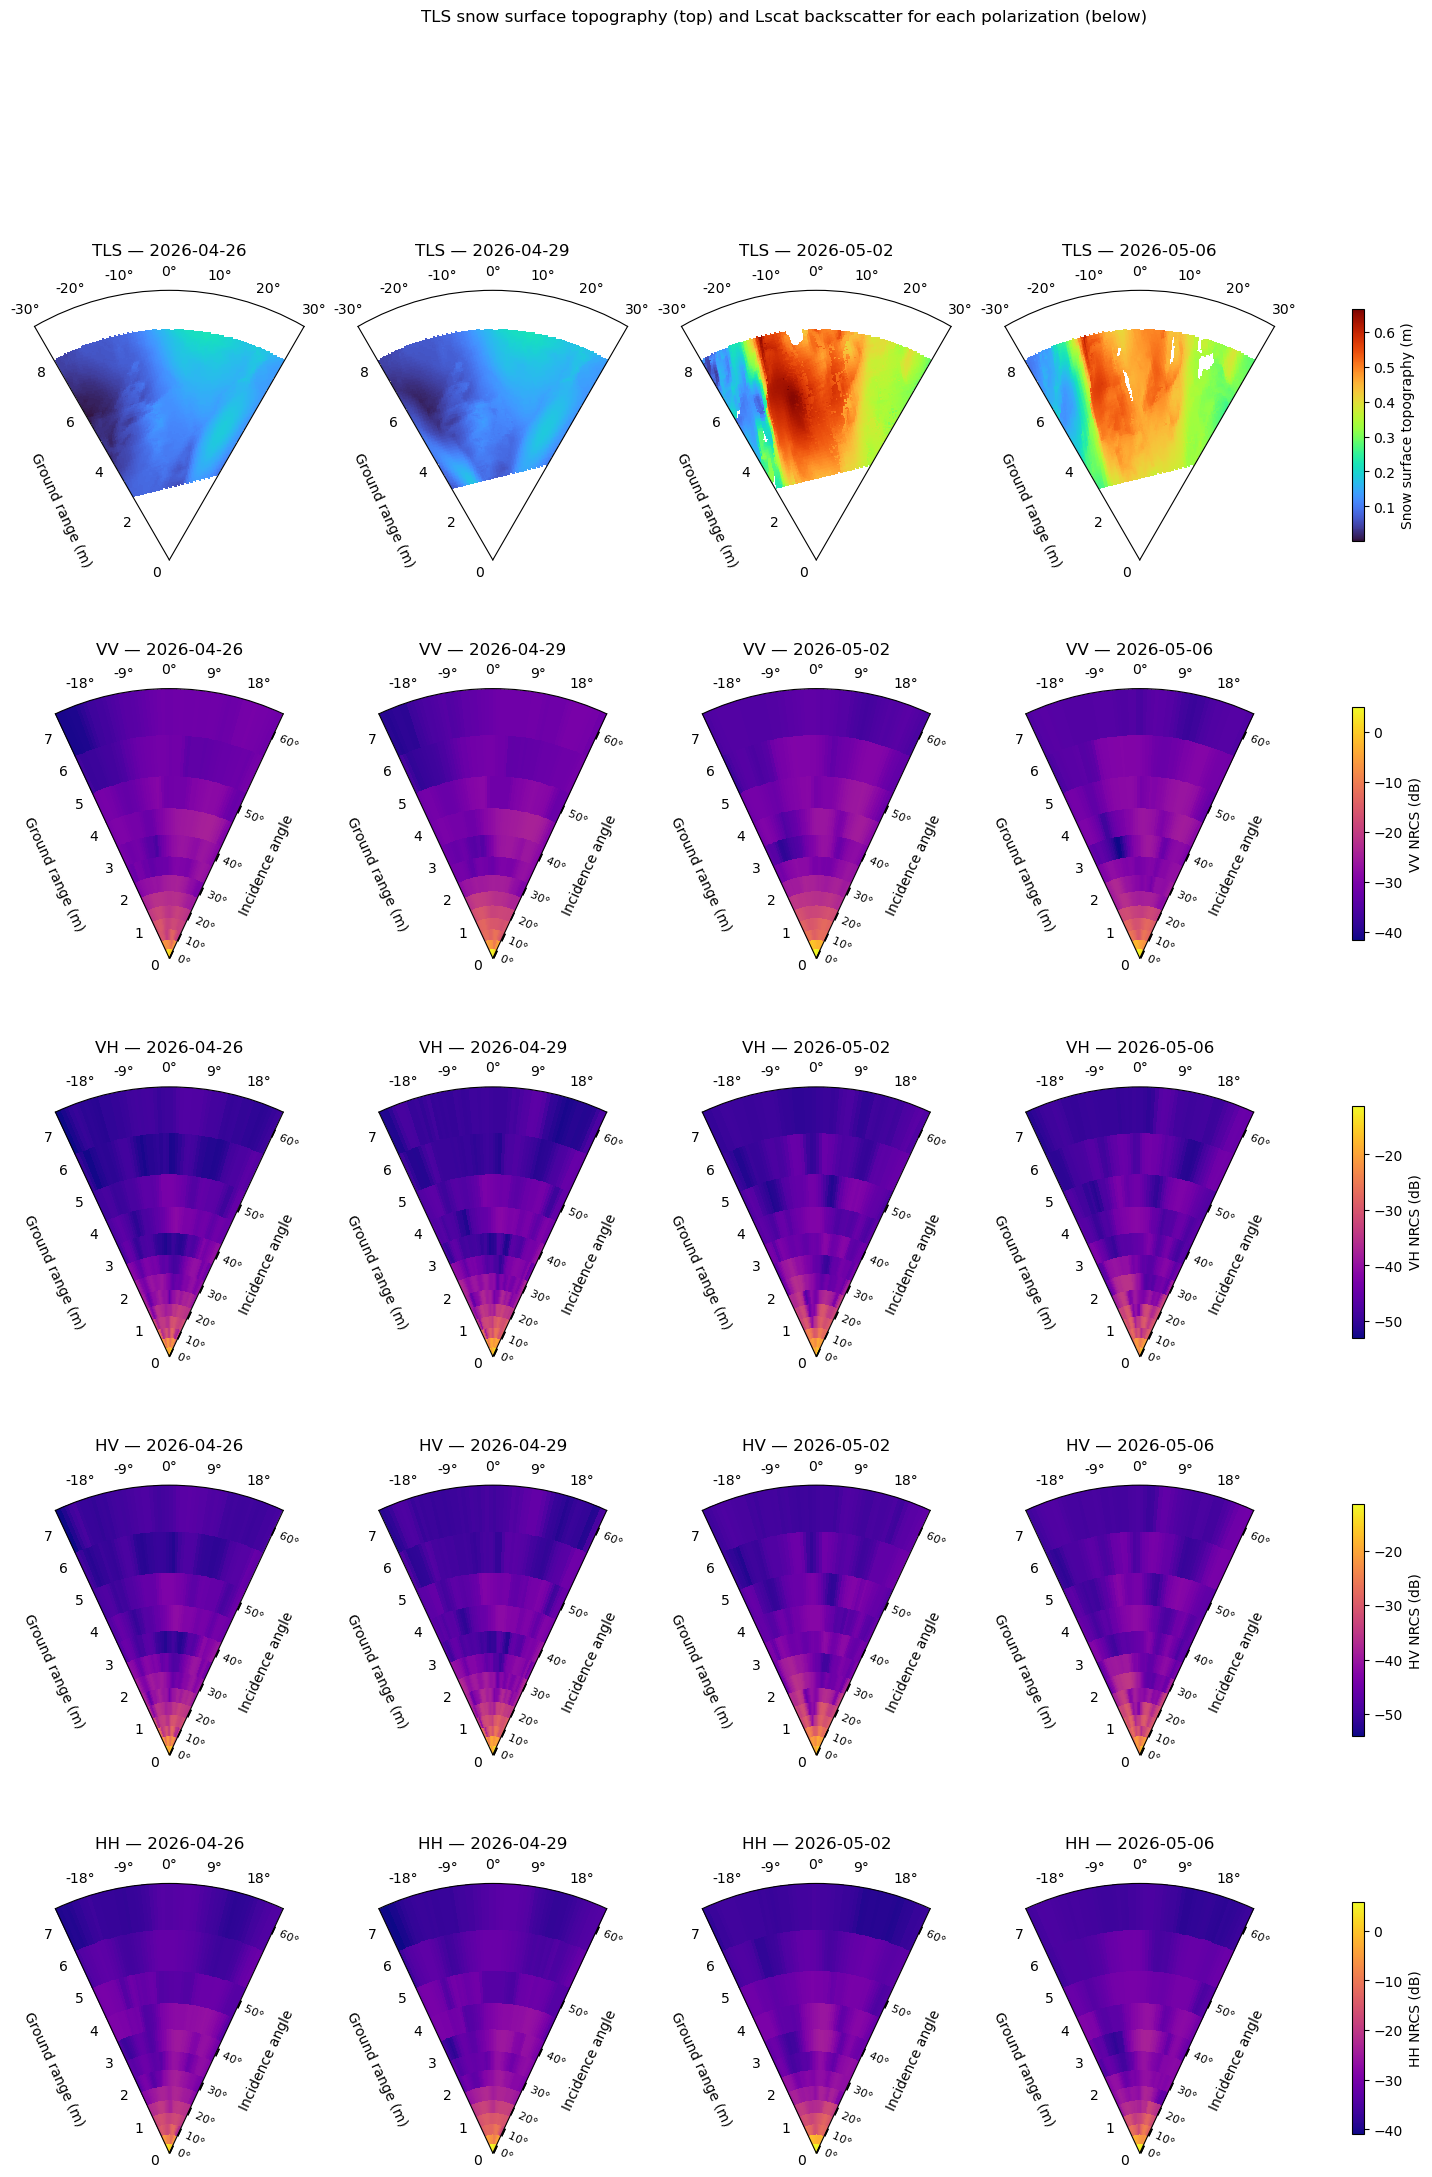

In [18]:
theta_rad = np.deg2rad(tls["theta"].values)  # angle from boresight, radians
r = tls["r"].values                          # distance from instrument, m

z_sel = tls["z"].sel(time=dates).values
vmin, vmax = np.nanmin(z_sel), np.nanmax(z_sel)  # shared color scale across all dates

az_rad = np.deg2rad(scat["az"].values)     # scatterometer azimuth, radians
ground_range = scat["ground_range"].values # scatterometer ground range, m
elev = scat["elev"].values                 # scatterometer incidence angle, deg

# NRCS averaged over every scat acquisition on each selected day, for every polarization
pols = scat["pol"].values  # VV, VH, HV, HH

nrcs_sel = {
    pol: [
        scat["nrcs"].sel(pol=pol).where(scat["time"].dt.date == date, drop=True).mean(dim="time", skipna=True)
        for date in dates
    ]
    for pol in pols
}
# color scale shared across dates, but computed separately for each polarization
nrcs_vmin = {pol: min(np.nanmin(n.values) for n in nrcs_sel[pol]) for pol in pols}
nrcs_vmax = {pol: max(np.nanmax(n.values) for n in nrcs_sel[pol]) for pol in pols}

# one column per date: TLS on the first row, then one row per polarization
fig, axs = plt.subplots(1 + len(pols), len(dates), figsize=(5 * len(dates), 5 * (1 + len(pols))), subplot_kw={"projection": "polar"})

for ax, date in zip(axs[0], dates):

    z = tls["z"].sel(time=date).values

    pcm = ax.pcolormesh(theta_rad, r, z, cmap="turbo", shading="auto", vmin=vmin, vmax=vmax)

    ax.set_thetamin(-30)
    ax.set_thetamax(30)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)  # positive angles on the right
    ax.set_title(f"TLS — {date}")
    ax.grid(False)

    # ground range label along the left edge, pushed further out to clear the radial tick labels
    edge = np.deg2rad(-30)
    label_offset = offset_copy(ax.transData, fig, x=-50 * np.cos(edge), y=50 * np.sin(edge), units="points")
    ax.text(edge, ground_range.max() / 2, "Ground range (m)", rotation=-65, rotation_mode="anchor", ha="center", va="center", transform=label_offset)

fig.colorbar(pcm, ax=axs[0], label="Snow surface topography (m)", shrink=0.7)

for row, pol in zip(axs[1:], pols):
    for ax, date, nrcs in zip(row, dates, nrcs_sel[pol]):

        pcm2 = ax.pcolormesh(az_rad, ground_range, nrcs.values, cmap="plasma", shading="auto", vmin=nrcs_vmin[pol], vmax=nrcs_vmax[pol])

        ax.set_thetamin(-25)
        ax.set_thetamax(25)
        ax.set_theta_zero_location("N")
        ax.set_theta_direction(-1)  # positive angles on the right
        ax.set_title(f"{pol} — {date}")
        ax.grid(False)

        # incidence angle axis along the right edge of the footprint (ground range is on the left edge)
        edge = np.deg2rad(25)
        for e, g in zip(elev, ground_range):
            if e % 10:
                continue
            ax.plot([edge, edge], [g, g], marker=(2, 0, -25), color="k", ms=6, clip_on=False)
            ax.text(edge, g, f"  {e}°", rotation=-25, rotation_mode="anchor", ha="left", va="center", fontsize=8)
        label_offset = offset_copy(ax.transData, fig, x=35 * np.cos(-edge), y=35 * np.sin(-edge), units="points")
        ax.text(edge, ground_range.max() / 2, "Incidence angle", rotation=65, rotation_mode="anchor", ha="center", va="center", transform=label_offset)

        # ground range label along the left edge, pushed further out to clear the radial tick labels
        label_offset = offset_copy(ax.transData, fig, x=-50 * np.cos(-edge), y=50 * np.sin(-edge), units="points")
        ax.text(-edge, ground_range.max() / 2, "Ground range (m)", rotation=-65, rotation_mode="anchor", ha="center", va="center", transform=label_offset)

    fig.colorbar(pcm2, ax=row, label=f"{pol} NRCS (dB)", shrink=0.7)

fig.suptitle("TLS snow surface topography (top) and Lscat backscatter for each polarization (below)")

If you want to further analyse these data, here are some ideas:
- plot maps of the copol (HH/VV) or crosspol (HV/HH) ratios
- select a specific area within the footprint (e.g. on flat snow or on the dune edge) and recalculate the time series
- plot animations